In [1]:
import pandas as pd
df=pd.read_csv('../data/2025/php_presence.csv')
df.head()

,client,total_origins,php_origins,pct_php
0,mobile,15889469,8274963,52.08
1,desktop,11989380,6215414,51.84


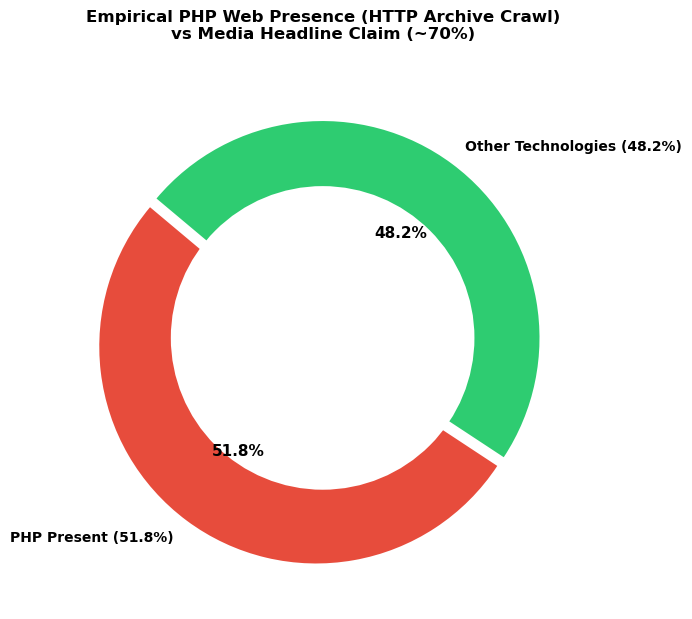

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# ----------------------------------------------------
# Opzione A: Se vuoi usare i dati del tuo DataFrame `df` importato da BigQuery
# Sostituisci 'desktop' o 'mobile' a seconda di quale riga vuoi rappresentare
# ----------------------------------------------------
# php_pct = df[df['client'] == 'desktop']['pct_php'].values[0]

# Opzione B: Usare direttamente la media aggregata (~52% PHP vs ~48% Altro)
php_pct = 51.84
other_pct = 100 - php_pct

# Valori e etichette per il grafico
labels = [f'PHP Present ({php_pct:.1f}%)', f'Other Technologies ({other_pct:.1f}%)']
sizes = [php_pct, other_pct]
colors = ['#e74c3c', '#2ecc71']

# Creazione del grafico Donut Chart (a ciambella)
fig, ax = plt.subplots(figsize=(7, 7))

wedges, texts, autotexts = ax.pie(
    sizes, 
    labels=labels, 
    autopct='%1.1f%%',
    startangle=140, 
    colors=colors, 
    explode=(0.05, 0),
    textprops=dict(color="black", fontweight='bold')
)

# Cerchio centrale per creare l'effetto ciambella
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Personalizzazione dei testi e titolo
plt.setp(autotexts, size=11, weight="bold")
plt.title('Empirical PHP Web Presence (HTTP Archive Crawl)\nvs Media Headline Claim (~70%)', fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()

# Salva l'immagine sul tuo PC per incollaria nel Google Doc
plt.savefig('../figures/2025/php_web_presence_donut.png', dpi=300, bbox_inches='tight')
plt.show()

In [3]:
df_version=pd.read_csv('../data/2025/version_disclosure.csv')
df_version.head()

,client,php_version,origins
0,mobile,7.4.33,642471
1,desktop,7.4.33,447208
2,mobile,8.2.29,222060
3,mobile,8.1.33,204816
4,mobile,8.2.28,153778


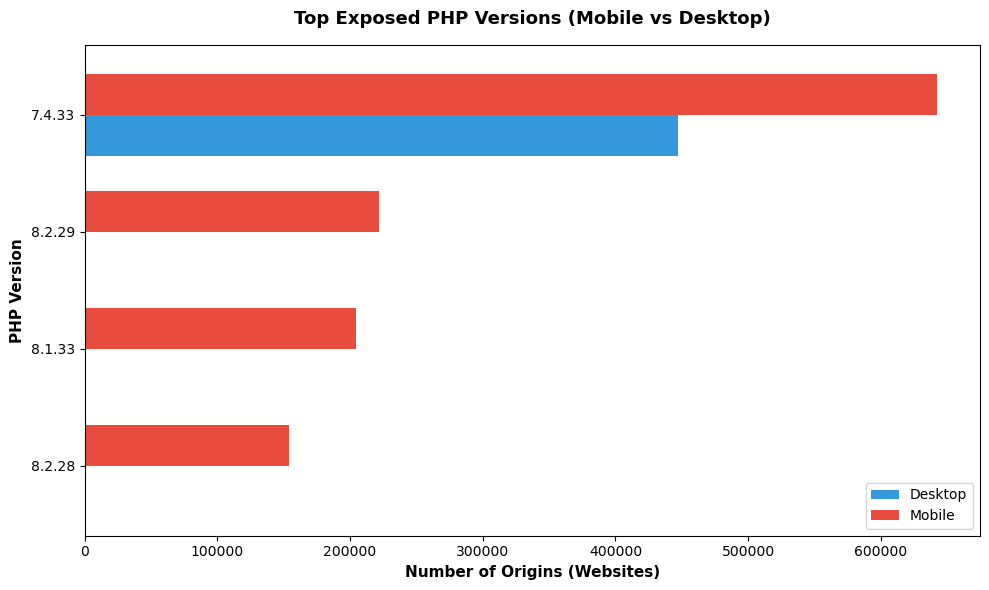

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Dati estratti da BigQuery
data = {
    'client': ['mobile', 'desktop', 'mobile', 'mobile', 'mobile'],
    'php_version': ['7.4.33', '7.4.33', '8.2.29', '8.1.33', '8.2.28'],
    'origins': [642471, 447208, 222060, 204816, 153778]
}

df = pd.DataFrame(data)

# Creazione di una tabella pivot per separare mobile e desktop per ogni versione
pivot_df = df.pivot(index='php_version', columns='client', values='origins').fillna(0)

# Ordiniamo per totale di siti (origins) in modo decrescente
pivot_df['total'] = pivot_df.sum(axis=1)
pivot_df = pivot_df.sort_values('total', ascending=True)
pivot_df = pivot_df.drop(columns='total')

fig, ax = plt.subplots(figsize=(10, 6))

# Grafico a barre orizzontali per leggere benissimo le versioni
pivot_df.plot(kind='barh', ax=ax, color=['#3498db', '#e74c3c'], width=0.7)

ax.set_ylabel('PHP Version', fontweight='bold', fontsize=11)
ax.set_xlabel('Number of Origins (Websites)', fontweight='bold', fontsize=11)
ax.set_title('Top Exposed PHP Versions (Mobile vs Desktop)', fontsize=13, fontweight='bold', pad=15)
ax.legend(['Desktop', 'Mobile'], loc='lower right')

plt.tight_layout()

# Salva l'immagine ad alta risoluzione con sfondo trasparente
plt.savefig('../figures/2025/php_versions_top_chart2025.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()